# LangChain 실습: 학습 카드 요청에 폴백과 비용 기록 붙이기

**이 노트북에서 할 일**

1. 03절 구조화 출력, 05절 폴백, 06절 비용 계산을 호출 객체 하나와 기록 함수로 조립합니다.
2. 기본 경로가 30초까지 기다리게 두고 학습 카드 두 장을 요청해, 응답한 모델과 비용을 기록합니다(실행 1).
3. 기본 경로의 기다리는 시간 하나만 0.001초로 바꿔 같은 요청을 보내고, 두 기록을 비교합니다(실행 2).

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 읽는 데이터 파일은 없습니다.

답을 받는 요청은 4번입니다. 모델별로는 `gpt-5.4-mini`에 2번, `gpt-5.4-nano`에 2번입니다.
실행 2에서는 답 없이 시간 초과로 끝나는 시도가 2번 더 있습니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만입니다(06절 4절의 2026-09-17 공식 요금 기준).

이 노트북은 파일을 만들거나 고치지 않습니다. 06절이 저장한 `runs` 폴더의 파일도 건드리지 않습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
pydantic 2.13.5, python-dotenv 1.2.3도 함께 씁니다. 함께 설치되는 openai 패키지는 3.10.0입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch06-langchain-start`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.
01~06절에서 쓴 이름만 씁니다. 강사와 함께 셀을 차례로 실행하며, 따로 내는 과제는 없습니다.

## 오늘 볼 그림

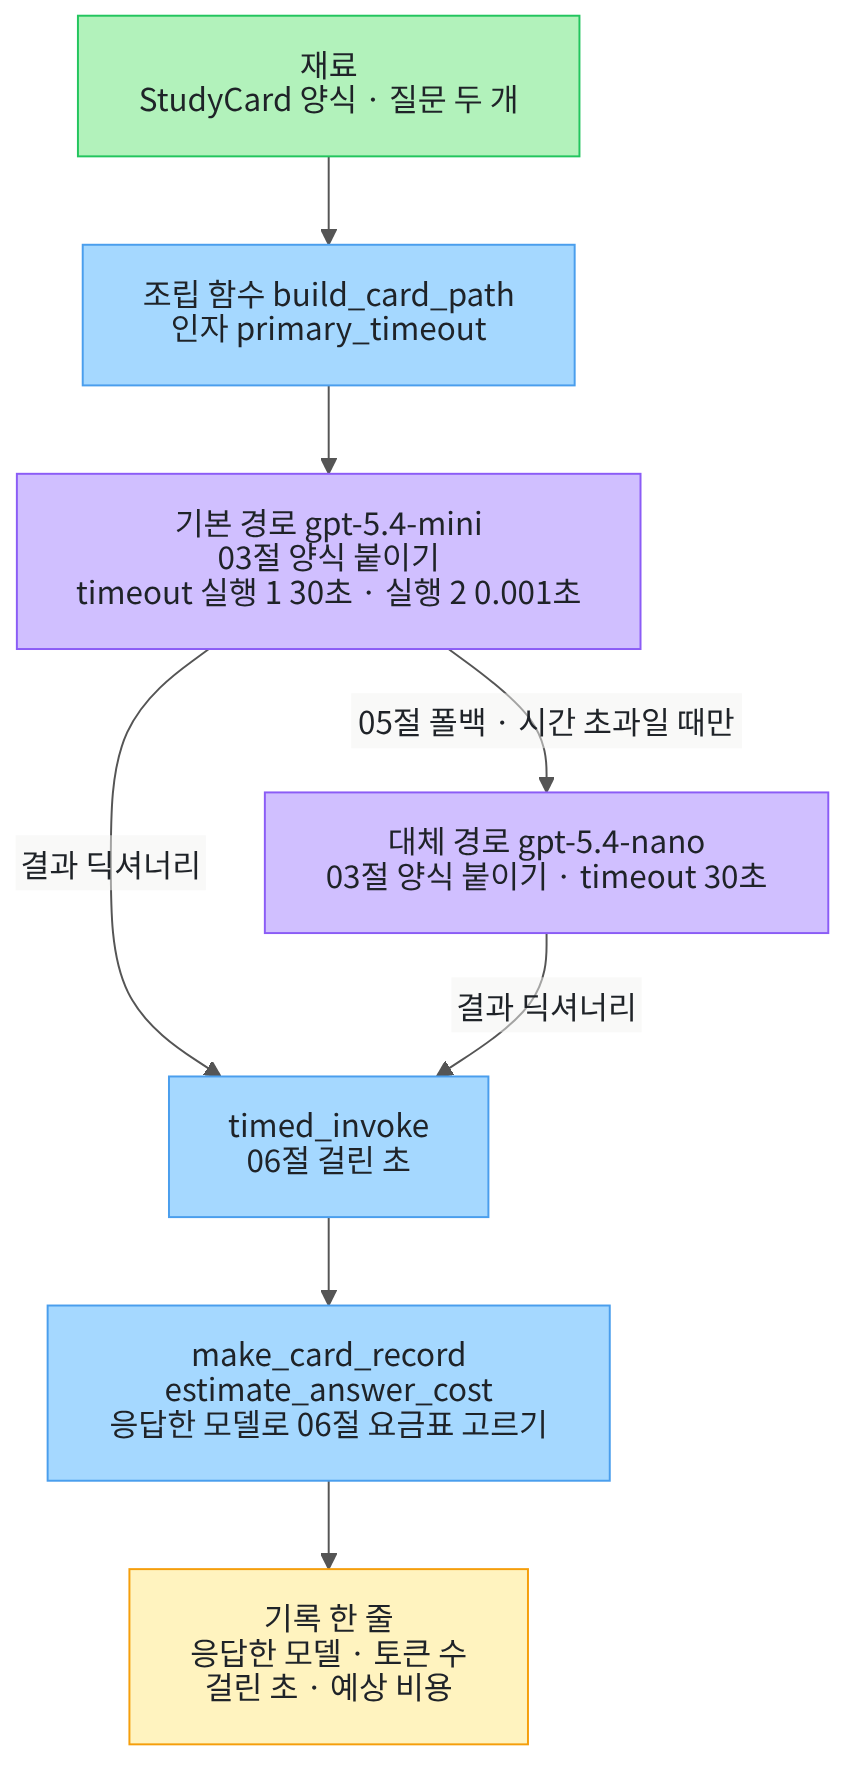

위에서 아래로 읽습니다. 초록 상자는 노트북에서 정한 카드 양식과 질문 두 개이고, 파란 상자는 노트북에서 정의한 함수입니다.
보라 상자 두 개는 답을 만드는 모델입니다. 기본 경로가 시간 초과로 실패하면 대체 경로로 넘어갑니다.
맨 아래 노란 상자가 요청마다 한 줄씩 남기는 기록입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
패키지 openai는 langchain-openai가 OpenAI 서버에 요청을 보낼 때 쓰는 패키지입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "pydantic==2.13.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("pydantic:", version("pydantic"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
pydantic: 2.13.5


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `openai: 3.10.0`, `pydantic: 2.13.5` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

이번 실습에서 쓸 이름을 불러옵니다. 모듈 `time`은 05·06절에서 걸린 시간을 잴 때 썼습니다.
오류 이름 `ModelTimeoutError`는 05절, 양식을 만드는 `BaseModel`과 `Field`는 03절에서 불러왔습니다.

In [2]:
# 걸린 시간을 재는 모듈, 모델 객체를 만드는 함수, 시간 초과 오류 이름, 양식 클래스 도구를 불러옵니다
import time

from langchain.chat_models import init_chat_model
from langchain_core.exceptions import ModelTimeoutError
from pydantic import BaseModel, Field

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델과 nano 모델로 실행한 결과입니다.
실행마다 카드 설명 문장, 토큰 수, 걸린 시간이 달라질 수 있습니다.

## 2. 실습 주제 — 학습 카드 요청에 폴백과 비용 기록 붙이기

초급 학습자에게 LangChain 용어 카드를 만들어 주는 작은 도우미를 떠올립니다. 카드는 03절 양식 `StudyCard`로 받습니다.
기본 경로 모델이 제시간에 답하지 못하면, 05절처럼 `gpt-5.4-nano`가 대신 답합니다.
요청마다 06절처럼 토큰 수, 걸린 시간, 예상 비용을 한 줄에 기록합니다.

기록에서 눈여겨볼 키는 응답한 모델입니다. 대체 경로가 답했으면 요금표도 nano의 것을 써야 합니다.
그래서 이 실습은 응답한 모델 이름을 보고 요금표를 고르는 함수를 만듭니다.

실행 1은 기본 경로가 30초까지 기다립니다. 실행 2는 기다리는 시간 하나만 05절 5절의 0.001초로 바꿉니다.
04절 스트리밍과 05절 `with_retry()`는 이번 실습에서 쓰지 않습니다.

먼저 준비 셀에서 만든 모델 객체 `model`의 두 설정을 봅니다. 05절 3절처럼 두 값을 적지 않은 모델입니다.

실행 전에 예상합니다. 두 값 모두 `None`일 것입니다.

In [5]:
# 준비 셀의 모델 객체에 적힌 기다리는 시간과 다시 시도 횟수를 봅니다(요청 없음)
print("모델 객체 timeout:", model.request_timeout)
print("모델 객체 max_retries:", model.max_retries)

모델 객체 timeout: None
모델 객체 max_retries: None


**결과 읽기** — 출력 줄은 `모델 객체 timeout: None`과 `모델 객체 max_retries: None`입니다. 예상과 같습니다.

05절 3절에서 본 것처럼, 이 모델은 기다리는 시간에 제한이 없습니다. 다시 시도는 openai 클라이언트의 기본값 2번을 따릅니다.
그래서 조립할 때는 두 경로 모두 두 값을 직접 적습니다. 이 `model`은 이 뒤로 요청에 쓰지 않습니다.

## 3. 재료 만들기 — 카드 양식과 질문 두 개

카드 양식은 03절과 같은 코드입니다. 칸은 개념 이름, 한 문장 설명, 난이도 세 개입니다.
난이도 칸에는 `Field(ge=1, le=3)`로 1부터 3까지라는 범위 규칙을 적습니다. 이 셀은 양식을 정의만 합니다.

In [6]:
# 개념 이름·설명·난이도 세 칸을 가진 학습 카드 양식을 정합니다(03절과 같은 코드)
class StudyCard(BaseModel):
    concept: str = Field(description="개념 이름")
    explanation: str = Field(description="한 문장 설명")
    difficulty: int = Field(ge=1, le=3, description="1부터 3까지의 난이도")

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

질문은 이 챕터에서 배운 이름 두 개의 카드를 만들어 달라는 요청입니다. 05절의 `with_fallbacks`와 01·06절의 `usage_metadata`입니다.
system 지시는 03절의 「초급 학습자를 위한 학습 카드를 만듭니다.」를 다시 씁니다. 질문마다 이 지시와 질문을 튜플 목록으로 묶어 보냅니다.

실행 전에 예상합니다. 질문 수는 2일 것입니다.

In [7]:
# 03절 system 지시 튜플과, 이 챕터에서 배운 이름 두 개의 카드를 요청하는 질문을 담습니다
system_message = ("system", "초급 학습자를 위한 학습 카드를 만듭니다.")
questions = [
    "LangChain의 with_fallbacks를 학습 카드로 만드세요. 개념 이름, 한 문장 설명, 1~3 난이도를 적으세요.",
    "LangChain의 usage_metadata를 학습 카드로 만드세요. 개념 이름, 한 문장 설명, 1~3 난이도를 적으세요.",
]
print("system 지시:", system_message[1])
print("질문 수:", len(questions))

system 지시: 초급 학습자를 위한 학습 카드를 만듭니다.
질문 수: 2


**결과 읽기** — 출력 줄은 `system 지시: 초급 학습자를 위한 학습 카드를 만듭니다.`와 `질문 수: 2`입니다.
아직 목록만 만들었고 요청은 보내지 않았습니다.

## 4. 재료 만들기 — 요금표와 비용 함수

두 모델의 요금표는 06절 4절과 같은 값입니다. 2026-09-17에 OpenAI 모델 페이지에서 확인한 100만 토큰당 달러입니다.

실행 전에 예상합니다. 두 딕셔너리에 키가 세 개씩 보일 것입니다.

In [8]:
# 06절 4절과 같은 두 모델의 공식 요금(100만 토큰당 달러)과 확인한 날짜를 적습니다
pricing_date = "2026-09-17"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
nano_prices = {"ordinary_input": 0.20, "cached_input": 0.02, "output": 1.25}
print("요금 확인 날짜:", pricing_date)
print("mini 요금:", mini_prices)
print("nano 요금:", nano_prices)

요금 확인 날짜: 2026-09-17
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}
nano 요금: {'ordinary_input': 0.2, 'cached_input': 0.02, 'output': 1.25}


**결과 읽기** — 출력 줄은 `요금 확인 날짜: 2026-09-17`, `mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}`, nano 요금 줄입니다.

다음은 06절과 같은 코드의 `estimate_cost()` 함수입니다. 사용량 딕셔너리와 세 요금으로 요청 한 번의 예상 비용을 계산합니다.
사용량이 `None`이면 `None`을, 캐시 입력 키가 없으면 캐시 입력을 0으로 봅니다. 이 셀은 함수를 정의만 합니다.

In [9]:
# 사용량 딕셔너리와 세 요금으로 요청 한 번의 예상 비용(달러)을 계산하는 함수를 정의합니다(06절과 같은 코드)
def estimate_cost(usage, input_rate, cached_input_rate, output_rate):
    if usage is None:
        return None
    # 캐시 입력 키가 없으면 할인 없이 모두 입력 요금으로 계산합니다
    details = usage.get("input_token_details", {})
    cache_read = details.get("cache_read", 0)
    normal_input = usage["input_tokens"] - cache_read
    input_cost = normal_input * input_rate + cache_read * cached_input_rate
    output_cost = usage["output_tokens"] * output_rate
    price_unit = 1000000
    return (input_cost + output_cost) / price_unit

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

다음 함수 `estimate_answer_cost()`는 원본 답 `AIMessage` 하나를 받습니다. 03절 8절에서 `include_raw=True`로 받은 `raw`가 이 객체입니다.
05절 10절처럼 응답 메타데이터의 `model_name`으로 응답한 모델 이름을 읽습니다.
이름에 nano가 들어 있으면 nano 요금표를, 아니면 mini 요금표를 골라 `estimate_cost()`를 부릅니다.

글자 포함 확인 `in`은 05절 10절 `assert "nano" in answered_model`에서 썼습니다. 이 셀도 함수를 정의만 합니다.

In [10]:
# 원본 답의 응답한 모델 이름으로 요금표를 골라 예상 비용을 반환하는 함수를 정의합니다
def estimate_answer_cost(raw_message):
    answered_model = raw_message.response_metadata["model_name"]
    # 대체 경로 nano가 답했으면 nano 요금표, 아니면 기본 경로 mini 요금표를 씁니다
    if "nano" in answered_model:
        prices = nano_prices
    else:
        prices = mini_prices
    run_usage = raw_message.usage_metadata
    return estimate_cost(run_usage, prices["ordinary_input"], prices["cached_input"], prices["output"])

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 5. 기록 장치 — 요청 한 번을 기록 한 줄로

첫 기록 함수는 06절과 같은 코드의 `timed_invoke()`입니다. 호출 객체로 메시지 목록을 보내고, 결과와 걸린 초를 튜플로 반환합니다.
06절에서는 모델 객체를 넣었지만, 메서드 `invoke()`가 있는 호출 객체라면 같은 방법으로 넣을 수 있습니다. 이 셀은 함수를 정의만 합니다.

In [11]:
# 호출 객체로 메시지 목록을 보내고, 결과와 걸린 초를 튜플로 반환하는 함수를 정의합니다(06절과 같은 코드)
def timed_invoke(run_model, input_messages):
    start_time = time.perf_counter()
    run_response = run_model.invoke(input_messages)
    run_elapsed = time.perf_counter() - start_time
    return run_response, run_elapsed

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

둘째 함수 `make_card_record()`는 03절 8절의 결과 딕셔너리와 걸린 초로 기록 한 줄을 만듭니다. 결과 딕셔너리의 키 `raw`에는 원본 답, `parsed`에는 읽은 카드가 있습니다.
기록 딕셔너리의 키는 8개입니다. 응답한 모델, 설명, 난이도, 입력·캐시 입력·출력 토큰 수, 걸린 초, 예상 비용입니다.

06절 `make_cost_record()`와 키가 달라서 이름을 따로 붙였습니다. 이 셀도 함수를 정의만 합니다.

In [12]:
# 구조화 호출의 결과 딕셔너리와 걸린 초로 기록 한 줄(딕셔너리)을 만드는 함수를 정의합니다
def make_card_record(result, run_elapsed):
    raw_message = result["raw"]
    run_usage = raw_message.usage_metadata
    record = {
        "응답한 모델": raw_message.response_metadata["model_name"],
        "설명": result["parsed"].explanation,
        "난이도": result["parsed"].difficulty,
        "입력 토큰 수": run_usage["input_tokens"],
        "캐시 입력 토큰 수": run_usage["input_token_details"]["cache_read"],
        "출력 토큰 수": run_usage["output_tokens"],
        "걸린 초": round(run_elapsed, 2),
        "예상 비용(달러)": estimate_answer_cost(raw_message),
    }
    return record

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

기록 한 줄을 키마다 한 줄씩 출력하는 함수는 Ch 4 06절과 Ch 5 09절의 `print_report()`를 그대로 가져옵니다.
이 셀도 함수를 정의만 합니다.

In [13]:
# Ch 4 06절·Ch 5 09절 함수: 기록 딕셔너리의 키와 값을 한 줄에 하나씩 출력합니다
def print_report(report):
    # items()는 키와 값의 짝을 차례로 내놓습니다
    for key, value in report.items():
        print(key, "|", value)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 이 함수는 실행 1과 실행 2에서 기록마다 부릅니다.

## 6. 조립하기 — 폴백을 붙인 구조화 호출 객체

먼저 대체 경로를 만듭니다. 02절의 `gpt-5.4-nano` 모델에 03절처럼 카드 양식을 붙입니다.
인자 `include_raw=True`를 주어 읽은 카드와 원본 답을 함께 받습니다. 원본 답에 사용량과 응답한 모델 이름이 들어 있기 때문입니다.

기다리는 시간은 30초, 다시 시도는 06절 5절처럼 0번으로 둡니다. 요청 한 번과 기록 한 줄을 맞추려는 설정입니다. 이 셀은 요청을 보내지 않습니다.

실행 전에 예상합니다. 03절 5절처럼 호출 객체 종류는 `RunnableSequence`일 것입니다.

In [14]:
# 대체 경로: nano 모델에 카드 양식을 붙이고 원본 답도 함께 받게 합니다(요청 없음)
backup_model = init_chat_model(
    "openai:gpt-5.4-nano", temperature=0, reasoning_effort="none",
    timeout=30, max_retries=0,
)
backup_path = backup_model.with_structured_output(StudyCard, include_raw=True)
print("대체 경로 호출 객체 종류:", type(backup_path).__name__)

대체 경로 호출 객체 종류: RunnableSequence


**결과 읽기** — 출력 줄은 `대체 경로 호출 객체 종류: RunnableSequence`입니다. 예상과 같습니다.

이제 조립 함수 `build_card_path()`를 정의합니다. 인자는 기본 경로의 기다리는 시간 하나입니다. 실행 1과 실행 2는 이 값만 바꿉니다.
함수 안에서 기본 경로 mini 모델을 만들고, 카드 양식을 붙이고, 시간 초과일 때만 대체 경로로 넘기게 합니다. 주석마다 그 줄을 배운 절을 적었습니다.

05절에서는 모델 객체에 `with_fallbacks()`를 붙였습니다. 여기서는 카드 양식을 붙인 호출 객체에 붙입니다.
05절 7절에서 호출 객체 `RunnableLambda(ask_current_model)`에 `with_retry()`를 붙인 것처럼, 03절의 호출 객체에도 같은 메서드가 있습니다. 새 메서드가 아니라 붙이는 자리만 다릅니다.

함수 안에서 바깥 이름 `backup_path`를 읽습니다.
이 셀은 함수를 정의만 합니다.

In [15]:
# 조립: 기본 경로 모델 → 카드 양식 → 시간 초과일 때 대체 경로로 넘기는 호출 객체를 반환합니다
def build_card_path(primary_timeout):
    # 01·05절: 기본 경로 mini 모델, 기다리는 시간은 인자로 받고 다시 시도는 끕니다
    primary_model = init_chat_model(
        "openai:gpt-5.4-mini", temperature=0, reasoning_effort="none",
        timeout=primary_timeout, max_retries=0,
    )
    # 03절: 카드 양식을 붙이고 원본 답도 함께 받습니다
    primary_path = primary_model.with_structured_output(StudyCard, include_raw=True)
    # 05절: 시간 초과 오류일 때만 대체 경로로 넘깁니다
    card_path = primary_path.with_fallbacks([backup_path], exceptions_to_handle=(ModelTimeoutError,))
    return card_path

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 조립이 끝났으니, 이제 기다리는 시간만 넣어 호출 객체를 만들면 됩니다.

## 7. 실행 1 — 기본 경로가 30초까지 기다리기

조립 함수에 30을 넣어 호출 객체를 만들고, 질문 두 개를 차례로 보냅니다. 요청이 모두 끝난 뒤 기록을 출력합니다.
06절 인계대로, 요청을 기다리는 반복문 안에서는 출력하지 않습니다.

응답한 모델 이름에 mini가 들어 있는지 `assert`로 확인합니다. 설명 문장과 난이도는 실행마다 달라질 수 있어 확인하지 않습니다.

실행 전에 예상합니다. 호출 객체 종류는 05절 10절의 `RunnableWithFallbacks`일 것입니다.
기본 경로가 제시간에 답하므로 두 기록 모두 응답한 모델이 mini이고, 난이도는 1~3 안일 것입니다.

In [16]:
# 실행 1: 기본 경로가 30초까지 기다리는 호출 객체로 질문 두 개를 보냅니다(요청 2번)
card_path = build_card_path(30)
records_1 = []
for question in questions:
    input_messages = [system_message, ("user", question)]
    result, run_elapsed = timed_invoke(card_path, input_messages)
    record = make_card_record(result, run_elapsed)
    records_1.append(record)
# 요청이 모두 끝난 뒤 호출 객체 종류와 기록을 출력합니다
print("호출 객체 종류:", type(card_path).__name__)
for record in records_1:
    print("기록:")
    print_report(record)
    assert "mini" in record["응답한 모델"]

호출 객체 종류: RunnableWithFallbacks
기록:
응답한 모델 | gpt-5.4-mini-2026-03-17
설명 | 주요 체인이 실패하거나 원하는 결과를 내지 못할 때, 미리 정해둔 대체 체인으로 자동 전환해 더 안정적으로 동작하게 하는 기능입니다.
난이도 | 2
입력 토큰 수 | 190
캐시 입력 토큰 수 | 0
출력 토큰 수 | 64
걸린 초 | 1.41
예상 비용(달러) | 0.0004305
기록:
응답한 모델 | gpt-5.4-mini-2026-03-17
설명 | LangChain의 usage_metadata는 모델 호출에서 사용된 입력·출력 토큰 수 같은 사용량 정보를 기록해 비용과 성능을 확인하는 데 쓰입니다.
난이도 | 2
입력 토큰 수 | 188
캐시 입력 토큰 수 | 0
출력 토큰 수 | 57
걸린 초 | 1.15
예상 비용(달러) | 0.0003975


**결과 읽기** — 첫 줄은 `호출 객체 종류: RunnableWithFallbacks`입니다. 두 기록 모두 `응답한 모델 | gpt-5.4-mini-2026-03-17`이고, `assert`도 통과했습니다.
첫 기록은 `입력 토큰 수 | 190`, `출력 토큰 수 | 64`, `걸린 초 | 1.41`, `예상 비용(달러) | 0.0004305`입니다.

둘째 기록은 입력 188토큰, 출력 57토큰이었습니다. 두 카드의 난이도는 모두 2로, 03절 범위 규칙 1~3 안이었습니다.
설명 키에는 카드마다 한 문장 설명이 들어 있습니다. 실행마다 문장이 달라질 수 있습니다.

첫 기록의 비용은 06절 식으로 `(190 × 0.75 + 64 × 4.50) ÷ 1000000`입니다. 괄호 안은 142.5 + 288 = 430.5입니다.
입력 190토큰은 06절 짧은 요청의 27토큰보다 훨씬 많습니다. 질문이 길고, 구조화 호출은 카드 양식을 요청에 함께 싣기 때문입니다.

## 8. 실행 2 — 기다리는 시간 하나만 0.001초로

바꾸는 값은 조립 함수에 넣는 기다리는 시간 하나입니다. 05절 5절에서 시간 초과 오류를 실제로 낸 0.001초를 넣습니다.
질문, 카드 양식, 대체 경로, 기록 함수는 그대로입니다.

응답한 모델 이름에 nano가 들어 있는지 `assert`로 확인합니다. 기본 경로가 시간 초과로 실패했다면 매번 대체 경로가 답해야 하기 때문입니다.

실행 전에 예상합니다. 두 기록 모두 응답한 모델이 nano일 것입니다. 시간 초과 오류는 폴백이 받아 넘기므로 출력에 나오지 않을 것입니다.
예상 비용은 nano 요금표로 계산되어 실행 1보다 작을 것입니다.

In [17]:
# 실행 2: 기본 경로의 기다리는 시간만 0.001초로 바꿔 같은 질문 두 개를 보냅니다(시도 4번, 답 2번)
card_path = build_card_path(0.001)
records_2 = []
for question in questions:
    input_messages = [system_message, ("user", question)]
    result, run_elapsed = timed_invoke(card_path, input_messages)
    record = make_card_record(result, run_elapsed)
    records_2.append(record)
# 요청이 모두 끝난 뒤 호출 객체 종류와 기록을 출력합니다
print("호출 객체 종류:", type(card_path).__name__)
for record in records_2:
    print("기록:")
    print_report(record)
    assert "nano" in record["응답한 모델"]

호출 객체 종류: RunnableWithFallbacks
기록:
응답한 모델 | gpt-5.4-nano-2026-03-17
설명 | with_fallbacks는 실행 중 오류가 나거나 응답이 실패할 때, 미리 지정한 대체(폴백) 실행 경로로 자동 전환해 안정적으로 결과를 얻도록 하는 기능입니다.
난이도 | 2
입력 토큰 수 | 190
캐시 입력 토큰 수 | 0
출력 토큰 수 | 70
걸린 초 | 0.9
예상 비용(달러) | 0.0001255
기록:
응답한 모델 | gpt-5.4-nano-2026-03-17
설명 | LangChain에서 모델 호출 결과와 함께 제공되는 사용량 정보(예: 토큰 수, 비용/청구 관련 메타데이터)를 담은 필드입니다.
난이도 | 2
입력 토큰 수 | 188
캐시 입력 토큰 수 | 0
출력 토큰 수 | 59
걸린 초 | 1.1
예상 비용(달러) | 0.00011135


**결과 읽기** — 두 기록 모두 `응답한 모델 | gpt-5.4-nano-2026-03-17`이고, `assert`도 통과했습니다.
첫 기록은 `출력 토큰 수 | 70`, `걸린 초 | 0.9`, `예상 비용(달러) | 0.0001255`입니다. 입력 토큰 수는 실행 1과 같은 190과 188이었습니다.

바꾼 값은 기다리는 시간 하나였는데, 답한 모델이 바뀌었습니다. 출력에 시간 초과 오류는 보이지 않습니다.
폴백이 시간 초과 오류를 받아 대체 경로로 넘겼기 때문입니다. 기본 경로가 실패했다는 사실은 응답한 모델 이름으로 확인합니다.

첫 기록의 비용은 nano 요금표로 `(190 × 0.20 + 70 × 1.25) ÷ 1000000`입니다. 괄호 안은 38 + 87.5 = 125.5입니다.
걸린 초에는 기본 경로의 실패한 시도와 대체 경로의 요청이 함께 들어 있습니다. 두 시간을 따로 재지는 않았습니다.

## 9. 두 실행 비교하기

두 실행의 기록을 표 모양으로 나란히 놓고, 실행마다 예상 비용 합을 구합니다. 06절 7·8절 기록표와 같은 모양입니다.
튜플 목록 `runs`의 원소는 (실행 이름, 기록 목록) 튜플입니다.

실행 전에 예상합니다. 응답한 모델은 실행 1이 mini, 실행 2가 nano이고, 예상 비용 합은 실행 2가 더 작을 것입니다.

In [18]:
# 두 실행의 기록을 한 줄씩 나란히 출력하고, 실행마다 예상 비용 합을 구합니다(요청 없음)
runs = [("실행 1", records_1), ("실행 2", records_2)]
print("실행 | 응답한 모델 | 입력 | 캐시 입력 | 출력 | 걸린 초 | 예상 비용(달러)")
for run_name, run_records in runs:
    total_cost = 0
    for record in run_records:
        print(
            run_name, "|", record["응답한 모델"], "|", record["입력 토큰 수"], "|", record["캐시 입력 토큰 수"], "|",
            record["출력 토큰 수"], "|", record["걸린 초"], "|", record["예상 비용(달러)"],
        )
        total_cost = total_cost + record["예상 비용(달러)"]
    print(run_name, "| 예상 비용 합(달러):", round(total_cost, 6))

실행 | 응답한 모델 | 입력 | 캐시 입력 | 출력 | 걸린 초 | 예상 비용(달러)
실행 1 | gpt-5.4-mini-2026-03-17 | 190 | 0 | 64 | 1.41 | 0.0004305
실행 1 | gpt-5.4-mini-2026-03-17 | 188 | 0 | 57 | 1.15 | 0.0003975
실행 1 | 예상 비용 합(달러): 0.000828
실행 2 | gpt-5.4-nano-2026-03-17 | 190 | 0 | 70 | 0.9 | 0.0001255
실행 2 | gpt-5.4-nano-2026-03-17 | 188 | 0 | 59 | 1.1 | 0.00011135
실행 2 | 예상 비용 합(달러): 0.000237


**결과 읽기** — 라벨 줄 아래에 실행마다 기록 두 줄과 합계 한 줄이 나옵니다. 합계 줄은 `실행 1 | 예상 비용 합(달러): 0.000828`과 `실행 2 | 예상 비용 합(달러): 0.000237`입니다.
네 요청 모두 캐시 입력은 0이었습니다.

출력 토큰 수는 실행 1이 64·57, 실행 2가 70·59로, 실행 2가 더 많았습니다. 그런데도 비용 합은 실행 1이 실행 2의 약 3.5배였습니다.
nano 요금표가 입력과 출력 모두 mini보다 싸기 때문입니다.

걸린 초는 실행 1이 1.41·1.15초, 실행 2가 0.9·1.1초였습니다. 요청이 두 번씩뿐이라, 이 차이로 어느 경로가 늘 빠르다고 말하지 않습니다.

## 10. 응답한 모델을 적지 않았다면

실행 2의 기록을 응답한 모델 이름 없이, 기본 경로 이름 mini만 보고 계산했다고 해 봅니다. 그러면 요금표도 mini의 것을 고르게 됩니다.
실행 2 기록의 토큰 수를 사용량 딕셔너리 모양으로 다시 담아, mini 요금표로 `estimate_cost()`를 부릅니다.

실행 전에 예상합니다. mini 요금이 nano보다 비싸므로, 잘못 고른 요금표로 계산한 합이 더 클 것입니다.

In [19]:
# 실행 2의 토큰 수를 기본 경로 mini 요금표로 계산한 합과, 응답한 모델 요금표로 계산한 합을 비교합니다(요청 없음)
mini_price_total = 0
answered_price_total = 0
for record in records_2:
    token_usage = {
        "input_tokens": record["입력 토큰 수"],
        "output_tokens": record["출력 토큰 수"],
        "input_token_details": {"cache_read": record["캐시 입력 토큰 수"]},
    }
    wrong_cost = estimate_cost(token_usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"])
    mini_price_total = mini_price_total + wrong_cost
    answered_price_total = answered_price_total + record["예상 비용(달러)"]
print("응답한 모델 요금표로 계산한 합(달러):", round(answered_price_total, 6))
print("기본 경로 mini 요금표로 계산한 합(달러):", round(mini_price_total, 6))

응답한 모델 요금표로 계산한 합(달러): 0.000237
기본 경로 mini 요금표로 계산한 합(달러): 0.000864


**결과 읽기** — 출력 줄은 `응답한 모델 요금표로 계산한 합(달러): 0.000237`과 `기본 경로 mini 요금표로 계산한 합(달러): 0.000864`입니다.
토큰 수는 같은데, 요금표를 잘못 고르자 예상 비용 합이 약 3.6배로 커졌습니다.

기본 경로 이름만 기록했다면 실행 2의 비용을 이만큼 크게 어림했을 것입니다. 대체 경로가 답했다는 사실도 기록에서 사라집니다.
05절 10절에서 본 것처럼, 폴백을 붙인 요청은 응답한 모델 이름을 함께 기록합니다.

## 정리

- 03절 구조화 출력, 05절 폴백, 06절 비용 계산을 조립 함수 하나와 기록 함수로 이었습니다.
- 실행 1은 기본 경로 mini가 두 카드를 답했습니다. 실행 2는 기다리는 시간만 0.001초로 바꾸자 대체 경로 nano가 답했습니다.
- 폴백이 붙은 호출은 응답한 모델 이름을 기록해야, 요금표를 맞게 골라 예상 비용을 계산할 수 있습니다.

이 절로 Ch 6이 끝납니다. Ch 7 08절은 06절이 저장한 기록 파일을 읽어 실행 출처를 확인합니다.